In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/._Task07_Pancreas
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/._labelsTr
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/._imagesTr
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/._imagesTs
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/._dataset.json
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/dataset.json
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTs/pancreas_090.nii
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTs/pancreas_030.nii
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/ima

In [2]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import nibabel as nib

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from tqdm import tqdm

from scipy import ndimage

from sklearn.model_selection import train_test_split

from collections import Counter

print("="*60)
print("PANTHER-Net : Dataset Analysis")
print("="*60)

PANTHER-Net : Dataset Analysis


In [3]:
################################################################################
# PANTHER-Net: A Multi-Task Deep Learning Framework for Explainable
# Pancreatic Tumor Segmentation and Quantitative Analysis from 3D CT Images
################################################################################
#
# NOTEBOOK SECTION : PHASE 1 - DATASET ANALYSIS
# SUBSECTION        : 1.1 LOCATE DATASET
################################################################################

import os

print("="*80)
print("AVAILABLE DATASETS")
print("="*80)

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

AVAILABLE DATASETS
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/prksh830
/kaggle/input/datasets/prksh830/pancreaticcancerdataset
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTs
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/labelsTr
/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTr


In [4]:
################################################################################
# PANTHER-Net: A Multi-Task Deep Learning Framework for Explainable
# Pancreatic Tumor Segmentation and Quantitative Analysis from 3D CT Images
################################################################################
#
# NOTEBOOK SECTION : PHASE 1 - DATASET ANALYSIS
# SUBSECTION        : 1.2 DEFINE DATASET PATHS
################################################################################

import os

ROOT_PATH = "/kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas"

IMAGE_PATH = os.path.join(ROOT_PATH, "imagesTr")
LABEL_PATH = os.path.join(ROOT_PATH, "labelsTr")
TEST_PATH  = os.path.join(ROOT_PATH, "imagesTs")

print("="*80)
print("DATASET PATHS")
print("="*80)

print("Training Images :", IMAGE_PATH)
print("Training Labels :", LABEL_PATH)
print("Testing Images  :", TEST_PATH)

DATASET PATHS
Training Images : /kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTr
Training Labels : /kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/labelsTr
Testing Images  : /kaggle/input/datasets/prksh830/pancreaticcancerdataset/Pancreatic Cancer Dataset/Task07_Pancreas/imagesTs


In [5]:
################################################################################
# NOTEBOOK SECTION : PHASE 1 - DATASET ANALYSIS
# SUBSECTION        : 1.3 VERIFY DATASET
################################################################################

print("="*80)
print("TRAINING IMAGES :", len(os.listdir(IMAGE_PATH)))
print("TRAINING LABELS :", len(os.listdir(LABEL_PATH)))
print("TEST IMAGES     :", len(os.listdir(TEST_PATH)))
print("="*80)

TRAINING IMAGES : 283
TRAINING LABELS : 282
TEST IMAGES     : 146


In [6]:
################################################################################
# NOTEBOOK SECTION : PHASE 1 - DATASET ANALYSIS
# SUBSECTION        : 1.4 DISPLAY SAMPLE FILES
################################################################################

print("Training Images")
print(sorted(os.listdir(IMAGE_PATH))[:10])

print()

print("Training Labels")
print(sorted(os.listdir(LABEL_PATH))[:10])

print()

print("Testing Images")
print(sorted(os.listdir(TEST_PATH))[:10])

Training Images
['._pancreas_001.nii.gz', '._pancreas_004.nii.gz', 'pancreas_001.nii', 'pancreas_004.nii', 'pancreas_005.nii', 'pancreas_006.nii', 'pancreas_010.nii', 'pancreas_012.nii', 'pancreas_015.nii', 'pancreas_016.nii']

Training Labels
['._pancreas_004.nii.gz', 'pancreas_001.nii', 'pancreas_004.nii', 'pancreas_005.nii', 'pancreas_006.nii', 'pancreas_010.nii', 'pancreas_012.nii', 'pancreas_015.nii', 'pancreas_016.nii', 'pancreas_018.nii']

Testing Images
['._pancreas_002.nii.gz', '._pancreas_003.nii.gz', '._pancreas_023.nii.gz', '._pancreas_065.nii.gz', '._pancreas_161.nii.gz', '._pancreas_223.nii.gz', '._pancreas_403.nii.gz', 'pancreas_002.nii', 'pancreas_003.nii', 'pancreas_007.nii']


In [7]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.5 : DATASET INTEGRITY VERIFICATION
################################################################################

import os

# Ignore Mac metadata files
image_files = sorted([
    f for f in os.listdir(IMAGE_PATH)
    if (f.endswith(".nii") or f.endswith(".nii.gz")) and not f.startswith("._")
])

label_files = sorted([
    f for f in os.listdir(LABEL_PATH)
    if (f.endswith(".nii") or f.endswith(".nii.gz")) and not f.startswith("._")
])

test_files = sorted([
    f for f in os.listdir(TEST_PATH)
    if (f.endswith(".nii") or f.endswith(".nii.gz")) and not f.startswith("._")
])

print("="*80)
print("DATASET SUMMARY")
print("="*80)

print(f"Training Images : {len(image_files)}")
print(f"Training Labels : {len(label_files)}")
print(f"Testing Images  : {len(test_files)}")

print("="*80)

# Compare filenames
img_names = set([os.path.splitext(os.path.splitext(f)[0])[0] for f in image_files])
lbl_names = set([os.path.splitext(os.path.splitext(f)[0])[0] for f in label_files])

missing_labels = sorted(img_names - lbl_names)
missing_images = sorted(lbl_names - img_names)

print("Images without Labels :", len(missing_labels))
print("Labels without Images :", len(missing_images))

if len(missing_labels) > 0:
    print("\nMissing Labels")
    print(missing_labels)

if len(missing_images) > 0:
    print("\nMissing Images")
    print(missing_images)

print("="*80)

DATASET SUMMARY
Training Images : 281
Training Labels : 281
Testing Images  : 139
Images without Labels : 0
Labels without Images : 0


In [8]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.6 : READ DATASET INFORMATION
################################################################################

import json

json_file = os.path.join(ROOT_PATH, "dataset.json")

with open(json_file, "r") as f:
    dataset_info = json.load(f)

print("="*80)
print("DATASET INFORMATION")
print("="*80)

for key, value in dataset_info.items():
    print(f"{key} : {value}")

print("="*80)

DATASET INFORMATION
name : Pancreas
description : Pancreas and cancer segmentation
reference : Memorial Sloan Kettering Cancer Center 
licence : CC-BY-SA 4.0
relase : 1.0 04/05/2018
tensorImageSize : 3D
modality : {'0': 'CT'}
labels : {'0': 'background', '1': 'pancreas', '2': 'cancer'}
numTraining : 281
numTest : 139
training : [{'image': './imagesTr/pancreas_290.nii.gz', 'label': './labelsTr/pancreas_290.nii.gz'}, {'image': './imagesTr/pancreas_127.nii.gz', 'label': './labelsTr/pancreas_127.nii.gz'}, {'image': './imagesTr/pancreas_056.nii.gz', 'label': './labelsTr/pancreas_056.nii.gz'}, {'image': './imagesTr/pancreas_148.nii.gz', 'label': './labelsTr/pancreas_148.nii.gz'}, {'image': './imagesTr/pancreas_048.nii.gz', 'label': './labelsTr/pancreas_048.nii.gz'}, {'image': './imagesTr/pancreas_135.nii.gz', 'label': './labelsTr/pancreas_135.nii.gz'}, {'image': './imagesTr/pancreas_382.nii.gz', 'label': './labelsTr/pancreas_382.nii.gz'}, {'image': './imagesTr/pancreas_035.nii.gz', 'label': 

In [9]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.7 : SAMPLE CT VOLUME ANALYSIS
################################################################################

import nibabel as nib
import numpy as np

sample_case = image_files[0]

image = nib.load(os.path.join(IMAGE_PATH, sample_case))

volume = image.get_fdata()

print("="*80)
print("SAMPLE CT VOLUME")
print("="*80)

print("Case Name      :", sample_case)
print("Volume Shape   :", volume.shape)
print("Voxel Spacing  :", image.header.get_zooms())
print("Data Type      :", volume.dtype)
print("Minimum Value  :", np.min(volume))
print("Maximum Value  :", np.max(volume))
print("Mean Intensity :", np.mean(volume))
print("Std Intensity  :", np.std(volume))

print("="*80)

SAMPLE CT VOLUME
Case Name      : pancreas_001.nii
Volume Shape   : (512, 512, 110)
Voxel Spacing  : (np.float32(0.644531), np.float32(0.644531), np.float32(2.5))
Data Type      : float64
Minimum Value  : -1024.0
Maximum Value  : 3071.0
Mean Intensity : -450.0099096818404
Std Intensity  : 497.01847957749226


In [10]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.8 : SAMPLE SEGMENTATION ANALYSIS
################################################################################

sample_label = label_files[0]

mask = nib.load(os.path.join(LABEL_PATH, sample_label)).get_fdata()

print("="*80)
print("SEGMENTATION INFORMATION")
print("="*80)

labels = np.unique(mask)

print("Unique Labels :", labels)

for l in labels:
    print(f"Label {int(l)} : {np.sum(mask==l)} voxels")

print("="*80)

SEGMENTATION INFORMATION
Unique Labels : [0. 1. 2.]
Label 0 : 28770130 voxels
Label 1 : 39557 voxels
Label 2 : 26153 voxels


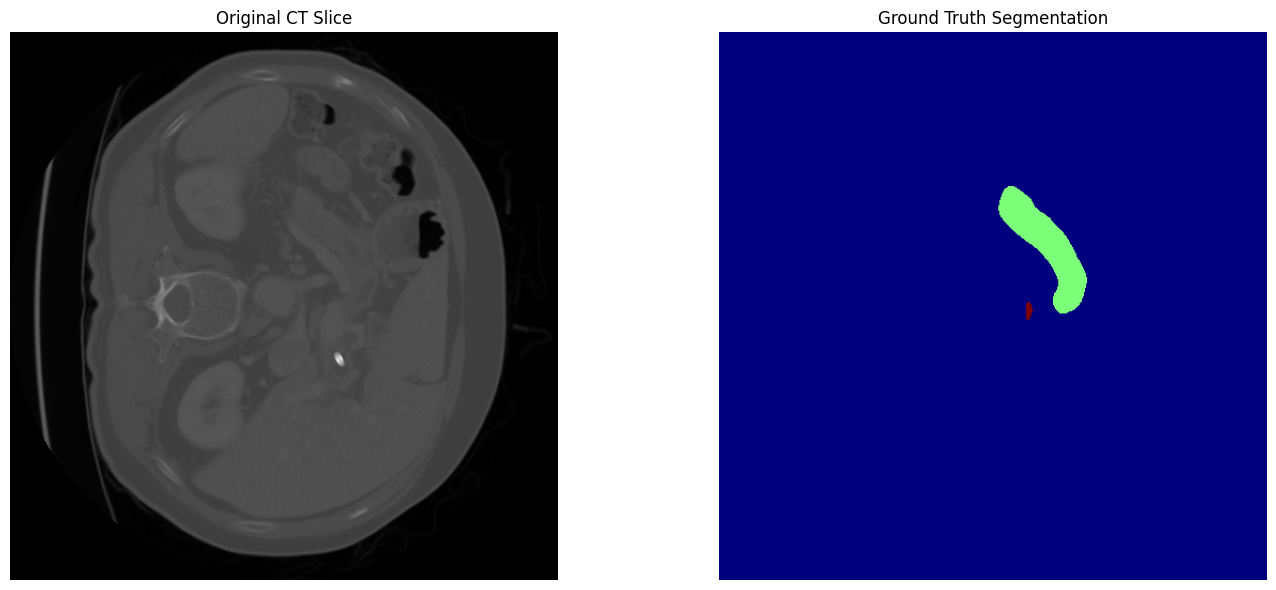

In [11]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.9 : VISUALIZE CT VOLUME AND MASK
################################################################################

import matplotlib.pyplot as plt

mid = volume.shape[2] // 2

plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.imshow(volume[:,:,mid], cmap='gray')
plt.title("Original CT Slice")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(mask[:,:,mid], cmap='jet')
plt.title("Ground Truth Segmentation")
plt.axis('off')

plt.tight_layout()

plt.savefig("Figure_01_CT_and_Mask.png",
            dpi=600,
            bbox_inches='tight')

plt.show()

In [12]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.10 : COMPLETE DATASET STATISTICS
################################################################################

import os
import nibabel as nib
import numpy as np
import pandas as pd

from tqdm import tqdm

statistics = []

for case in tqdm(image_files):

    image = nib.load(os.path.join(IMAGE_PATH, case))
    label = nib.load(os.path.join(LABEL_PATH, case))

    volume = image.get_fdata()
    mask = label.get_fdata()

    spacing = image.header.get_zooms()

    pancreas_voxels = np.sum(mask == 1)
    tumor_voxels = np.sum(mask == 2)

    statistics.append({

        "Case"              : case,

        "Height"            : volume.shape[0],
        "Width"             : volume.shape[1],
        "Depth"             : volume.shape[2],

        "VoxelSize_X"       : spacing[0],
        "VoxelSize_Y"       : spacing[1],
        "VoxelSize_Z"       : spacing[2],

        "MinimumHU"         : np.min(volume),
        "MaximumHU"         : np.max(volume),
        "MeanHU"            : np.mean(volume),
        "StdHU"             : np.std(volume),

        "PancreasVoxels"    : pancreas_voxels,
        "TumorVoxels"       : tumor_voxels,

        "TumorRatio"        : tumor_voxels /
                              (pancreas_voxels + tumor_voxels + 1e-8)

    })

dataset_statistics = pd.DataFrame(statistics)

print("="*90)
print(dataset_statistics.head())
print("="*90)

100%|██████████| 281/281 [06:30<00:00,  1.39s/it]

               Case  Height  Width  Depth  VoxelSize_X  VoxelSize_Y  \
0  pancreas_001.nii     512    512    110     0.644531     0.644531   
1  pancreas_004.nii     512    512    107     0.742188     0.742188   
2  pancreas_005.nii     512    512    104     0.917969     0.917969   
3  pancreas_006.nii     512    512    101     0.767578     0.767578   
4  pancreas_010.nii     512    512    174     0.976562     0.976562   

   VoxelSize_Z  MinimumHU  MaximumHU      MeanHU       StdHU  PancreasVoxels  \
0          2.5    -1024.0     3071.0 -450.009910  497.018480           39557   
1          2.5    -1024.0     2926.0 -503.111402  506.422214           71622   
2          2.5    -1024.0     2098.0 -623.373424  488.576016           71062   
3          2.5    -1024.0     3071.0 -579.820920  494.325853           70046   
4          1.5    -1024.0     2350.0 -514.041645  494.467457          116491   

   TumorVoxels  TumorRatio  
0        26153    0.398006  
1        28448    0.284281  
2    

In [13]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.11 : SAVE DATASET STATISTICS
################################################################################

dataset_statistics.to_csv(
    "Dataset_Statistics.csv",
    index=False
)

print("Dataset statistics saved successfully.")

Dataset statistics saved successfully.


In [14]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.12 : DATASET SUMMARY
################################################################################

print("="*80)

print(dataset_statistics.describe())

print("="*80)

       Height  Width       Depth  VoxelSize_X  VoxelSize_Y  VoxelSize_Z  \
count   281.0  281.0  281.000000   281.000000   281.000000   281.000000   
mean    512.0  512.0   95.085409     0.812373     0.812373     2.900178   
std       0.0    0.0   48.470976     0.094261     0.094261     0.980711   
min     512.0  512.0   37.000000     0.605469     0.605469     0.700012   
25%     512.0  512.0   83.000000     0.740234     0.740234     2.500000   
50%     512.0  512.0   93.000000     0.802734     0.802734     2.500000   
75%     512.0  512.0  103.000000     0.892578     0.892578     2.500000   
max     512.0  512.0  751.000000     0.976562     0.976562     7.500000   

         MinimumHU    MaximumHU      MeanHU       StdHU  PancreasVoxels  \
count   281.000000   281.000000  281.000000  281.000000      281.000000   
mean  -1036.469751  2088.249110 -572.874693  490.417013    47250.711744   
std     106.703093   733.054701   67.904275   36.791290    25758.463141   
min   -2048.000000  1141

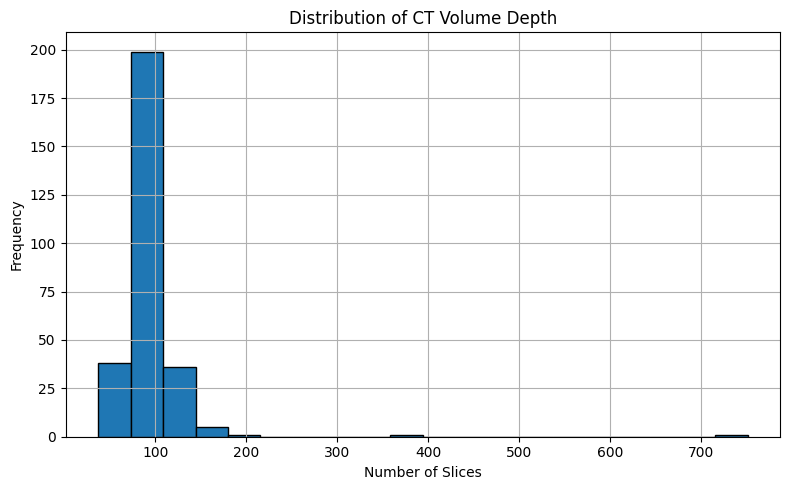

In [15]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.13 : IMAGE DIMENSION DISTRIBUTION
################################################################################

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(dataset_statistics["Depth"],
         bins=20,
         edgecolor='black')

plt.xlabel("Number of Slices")

plt.ylabel("Frequency")

plt.title("Distribution of CT Volume Depth")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_02_Depth_Distribution.png",
    dpi=600
)

plt.show()

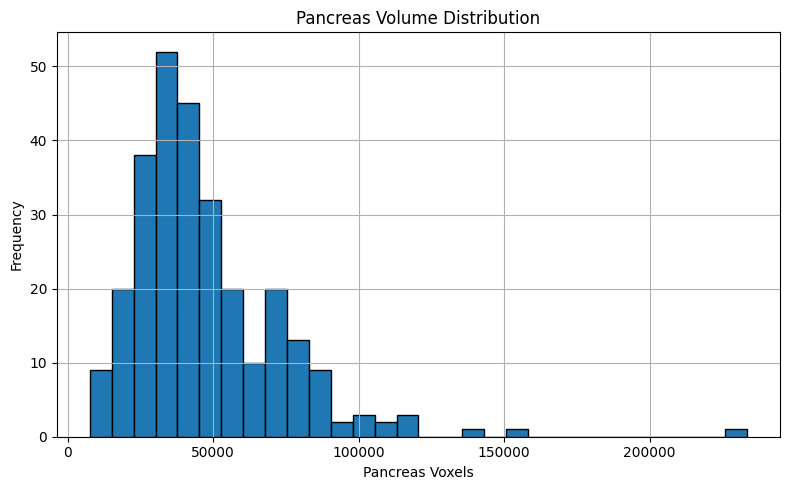

In [16]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.14 : PANCREAS SIZE DISTRIBUTION
################################################################################

plt.figure(figsize=(8,5))

plt.hist(dataset_statistics["PancreasVoxels"],
         bins=30,
         edgecolor='black')

plt.xlabel("Pancreas Voxels")

plt.ylabel("Frequency")

plt.title("Pancreas Volume Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_03_Pancreas_Distribution.png",
    dpi=600
)

plt.show()

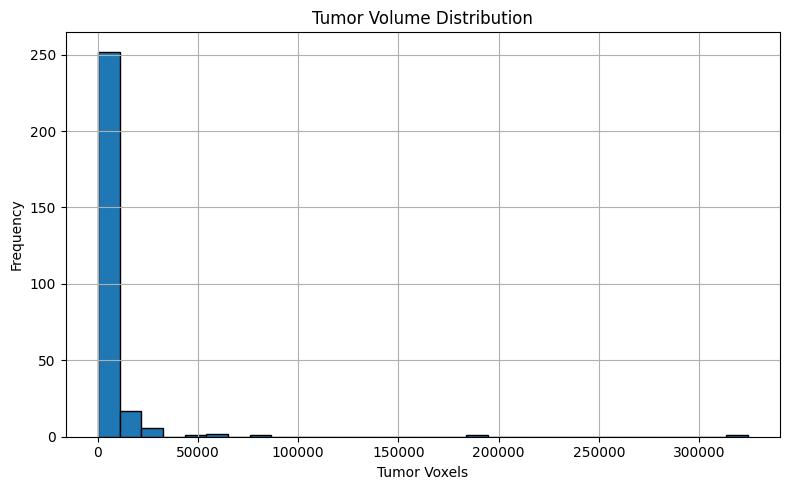

In [17]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.15 : TUMOR SIZE DISTRIBUTION
################################################################################

plt.figure(figsize=(8,5))

plt.hist(dataset_statistics["TumorVoxels"],
         bins=30,
         edgecolor='black')

plt.xlabel("Tumor Voxels")

plt.ylabel("Frequency")

plt.title("Tumor Volume Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_04_Tumor_Distribution.png",
    dpi=600
)

plt.show()

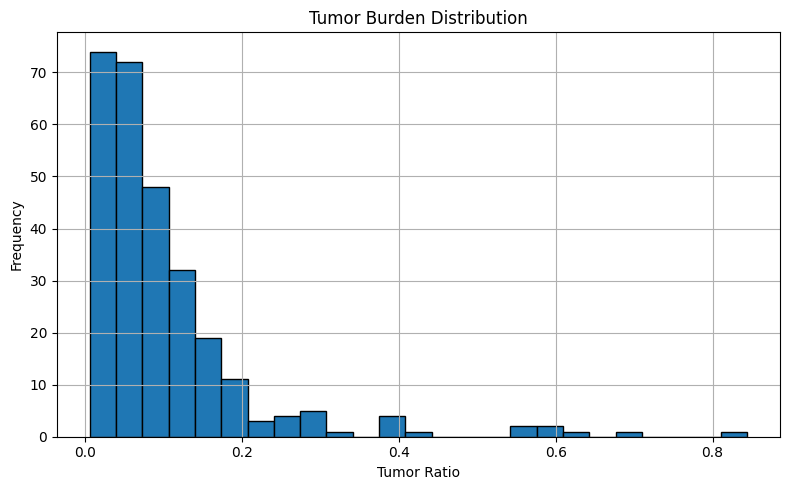

In [18]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.16 : TUMOR BURDEN DISTRIBUTION
################################################################################

plt.figure(figsize=(8,5))

plt.hist(dataset_statistics["TumorRatio"],
         bins=25,
         edgecolor='black')

plt.xlabel("Tumor Ratio")

plt.ylabel("Frequency")

plt.title("Tumor Burden Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_05_Tumor_Burden.png",
    dpi=600
)

plt.show()

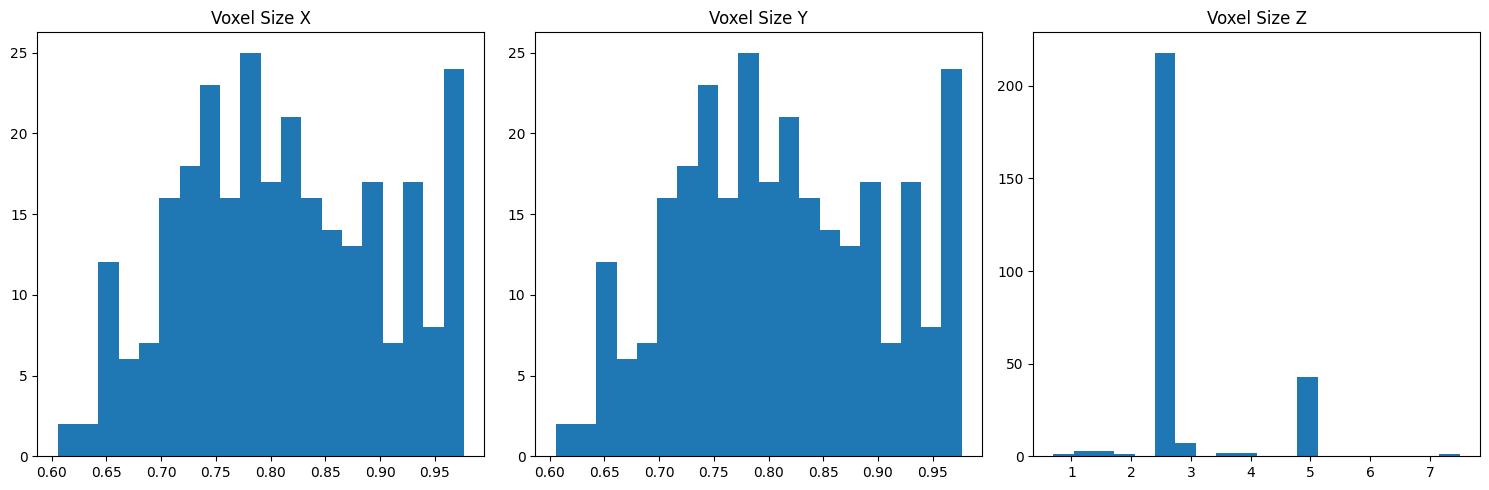

In [19]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.17 : VOXEL SPACING ANALYSIS
################################################################################

fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].hist(dataset_statistics["VoxelSize_X"], bins=20)
ax[0].set_title("Voxel Size X")

ax[1].hist(dataset_statistics["VoxelSize_Y"], bins=20)
ax[1].set_title("Voxel Size Y")

ax[2].hist(dataset_statistics["VoxelSize_Z"], bins=20)
ax[2].set_title("Voxel Size Z")

plt.tight_layout()

plt.savefig(
    "Figure_06_VoxelSpacing.png",
    dpi=600
)

plt.show()

100%|██████████| 281/281 [12:11<00:00,  2.60s/it]


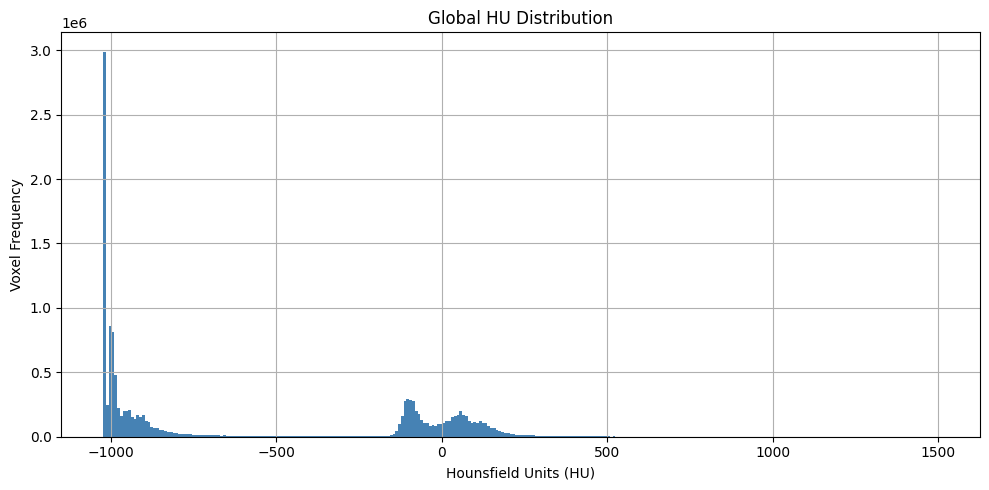

HU Statistics
Minimum : -2048.0
Maximum : 3071.0
Mean    : -573.0434213523132
Median  : -907.0
Std Dev : 496.4088318958431


In [20]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.18 : HOUNSFIELD UNIT (HU) DISTRIBUTION ANALYSIS
################################################################################

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

all_hu = []

for case in tqdm(image_files):

    img = nib.load(os.path.join(IMAGE_PATH, case)).get_fdata()

    # Randomly sample voxels to reduce memory usage
    sample = np.random.choice(img.flatten(),
                              size=min(50000, img.size),
                              replace=False)

    all_hu.extend(sample)

all_hu = np.array(all_hu)

plt.figure(figsize=(10,5))

plt.hist(all_hu,
         bins=300,
         range=(-1024,1500),
         color='steelblue')

plt.xlabel("Hounsfield Units (HU)")
plt.ylabel("Voxel Frequency")
plt.title("Global HU Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_07_Global_HU_Distribution.png",
    dpi=600)

plt.show()

print("="*80)
print("HU Statistics")
print("="*80)
print("Minimum :", np.min(all_hu))
print("Maximum :", np.max(all_hu))
print("Mean    :", np.mean(all_hu))
print("Median  :", np.median(all_hu))
print("Std Dev :", np.std(all_hu))

100%|██████████| 281/281 [01:13<00:00,  3.84it/s]


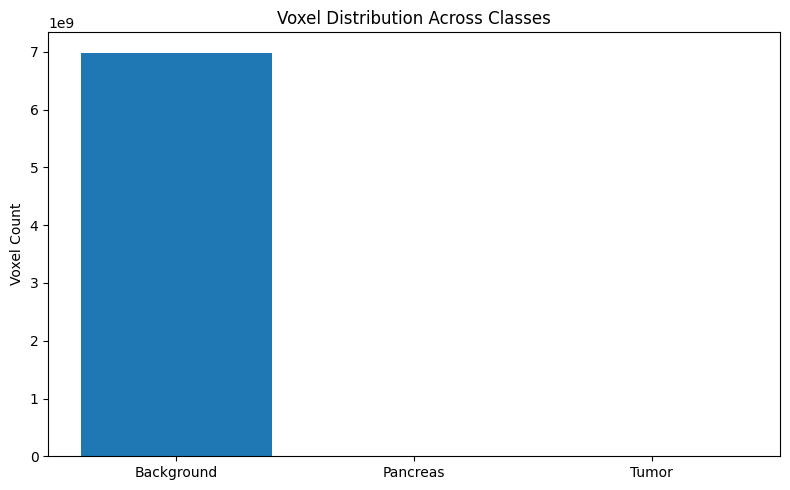

Voxel Distribution
Background : 6,988,952,255
Pancreas   : 13,277,450
Tumor      : 1,995,831


In [21]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.19 : CLASS VOXEL DISTRIBUTION
################################################################################

background = 0
pancreas = 0
tumor = 0

for case in tqdm(label_files):

    mask = nib.load(os.path.join(LABEL_PATH, case)).get_fdata()

    background += np.sum(mask == 0)
    pancreas += np.sum(mask == 1)
    tumor += np.sum(mask == 2)

labels = ["Background","Pancreas","Tumor"]
values = [background, pancreas, tumor]

plt.figure(figsize=(8,5))

plt.bar(labels,
        values)

plt.ylabel("Voxel Count")

plt.title("Voxel Distribution Across Classes")

plt.tight_layout()

plt.savefig(
    "Figure_08_Class_Distribution.png",
    dpi=600)

plt.show()

print("="*80)
print("Voxel Distribution")
print("="*80)

print(f"Background : {background:,}")
print(f"Pancreas   : {pancreas:,}")
print(f"Tumor      : {tumor:,}")

100%|██████████| 281/281 [00:00<00:00, 372.76it/s]


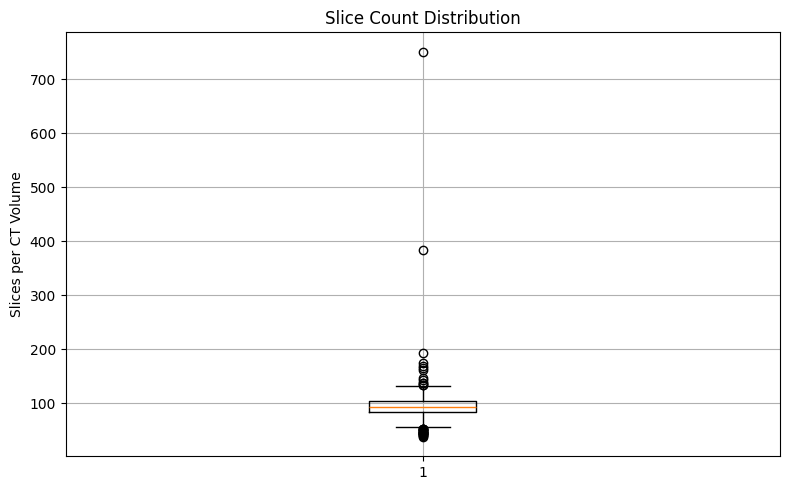

Slice Statistics
Minimum : 37
Maximum : 751
Mean    : 95.08540925266904
Median  : 93.0


In [22]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.20 : SLICE DISTRIBUTION
################################################################################

slice_count = []

for case in tqdm(image_files):

    img = nib.load(os.path.join(IMAGE_PATH, case))

    slice_count.append(img.shape[2])

slice_count = np.array(slice_count)

plt.figure(figsize=(8,5))

plt.boxplot(slice_count)

plt.ylabel("Slices per CT Volume")

plt.title("Slice Count Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Figure_09_Slice_Distribution.png",
    dpi=600)

plt.show()

print("="*80)
print("Slice Statistics")
print("="*80)

print("Minimum :", slice_count.min())
print("Maximum :", slice_count.max())
print("Mean    :", slice_count.mean())
print("Median  :", np.median(slice_count))

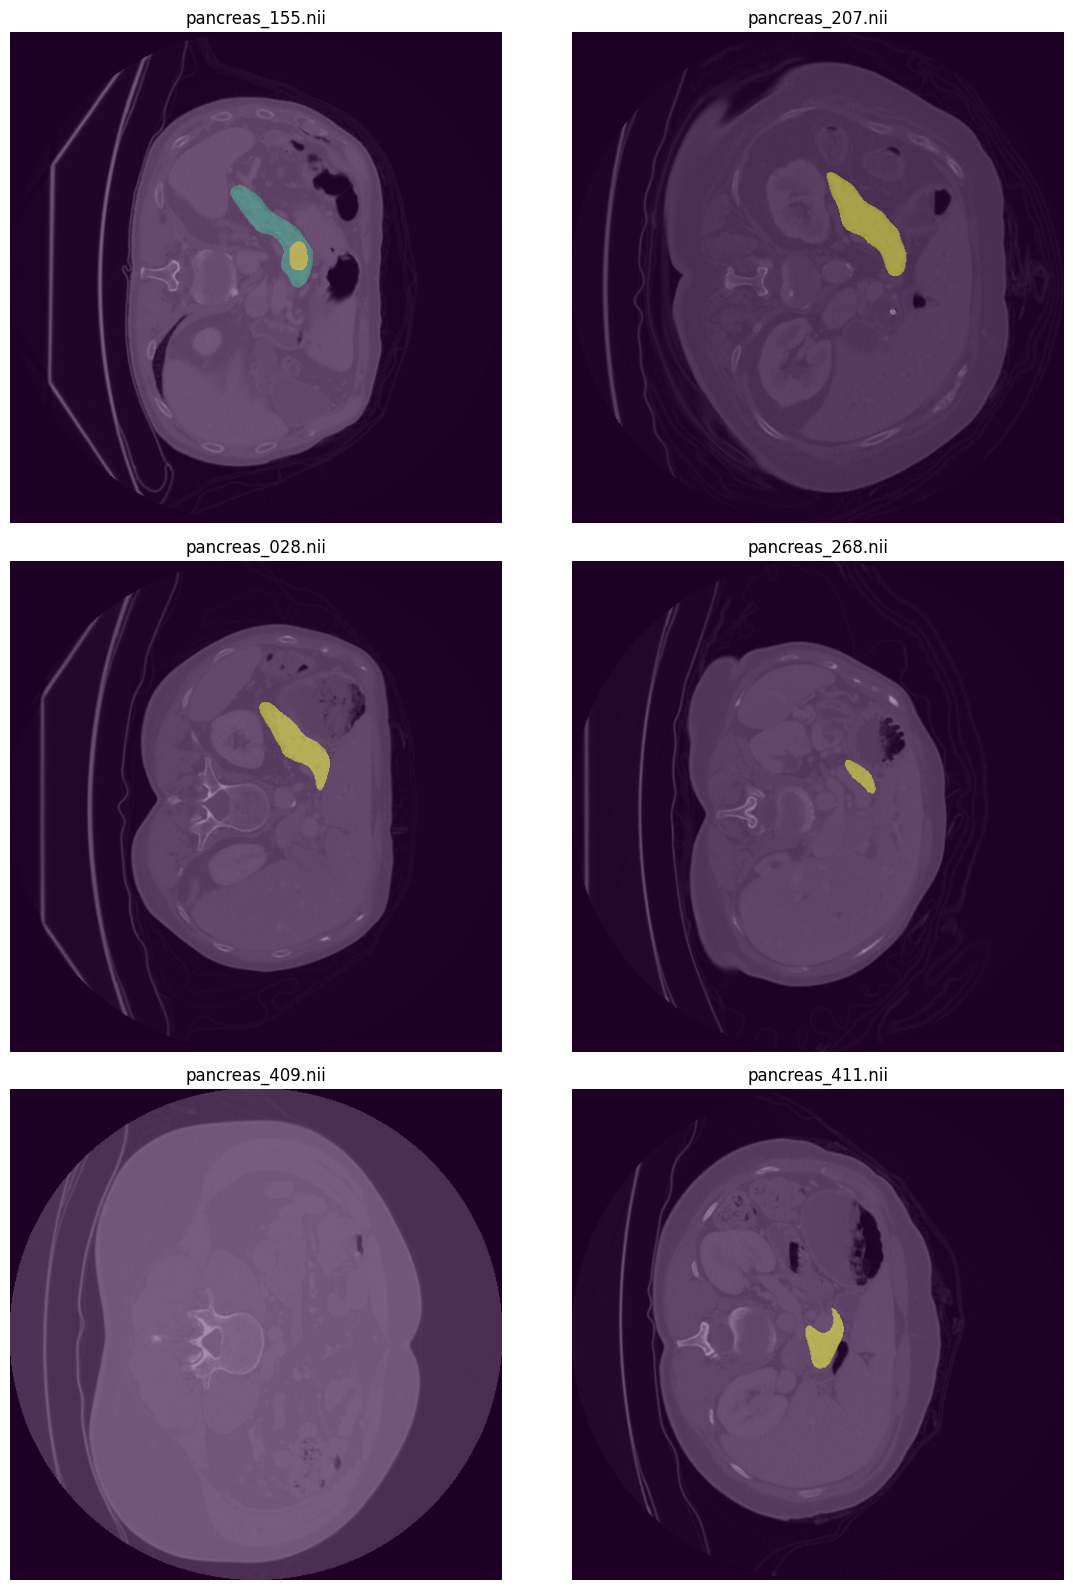

In [23]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.21 : RANDOM DATASET VISUALIZATION
################################################################################

import random

random_cases = random.sample(image_files, 6)

fig, axes = plt.subplots(3,2, figsize=(12,16))

axes = axes.flatten()

for ax, case in zip(axes, random_cases):

    img = nib.load(os.path.join(IMAGE_PATH, case)).get_fdata()
    mask = nib.load(os.path.join(LABEL_PATH, case)).get_fdata()

    mid = img.shape[2]//2

    ax.imshow(img[:,:,mid], cmap='gray')
    ax.imshow(mask[:,:,mid], alpha=0.45)

    ax.set_title(case)

    ax.axis('off')

plt.tight_layout()

plt.savefig(
    "Figure_10_Random_Cases.png",
    dpi=600)

plt.show()

In [24]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.22 : EXPORT DATASET REPORT
################################################################################

summary = pd.DataFrame({

"Training Cases":[len(image_files)],
"Testing Cases":[len(test_files)],
"Average Height":[dataset_statistics["Height"].mean()],
"Average Width":[dataset_statistics["Width"].mean()],
"Average Depth":[dataset_statistics["Depth"].mean()],
"Average Pancreas Voxels":[dataset_statistics["PancreasVoxels"].mean()],
"Average Tumor Voxels":[dataset_statistics["TumorVoxels"].mean()],
"Average Tumor Ratio":[dataset_statistics["TumorRatio"].mean()]

})

summary.to_csv("Dataset_Report.csv",index=False)

summary

,Training Cases,Testing Cases,Average Height,Average Width,Average Depth,Average Pancreas Voxels,Average Tumor Voxels,Average Tumor Ratio
0,281,139,512.0,512.0,95.085409,47250.711744,7102.601423,0.102071


In [25]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.1 : CREATE OUTPUT DIRECTORIES
################################################################################

import os

OUTPUT_ROOT = "/kaggle/working/PANTHER_Output"

folders = [
    "Preprocessed_Images",
    "Preprocessed_Labels",
    "Figures",
    "Statistics",
    "Models",
    "Predictions",
    "Logs"
]

for folder in folders:
    os.makedirs(os.path.join(OUTPUT_ROOT, folder), exist_ok=True)

print("="*80)
print("Output directories created successfully.")
print("="*80)

Output directories created successfully.


In [26]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.2 : CT WINDOW ANALYSIS
################################################################################

WINDOW_MIN = -150
WINDOW_MAX = 250

print("="*80)
print("Window Level")
print("="*80)

print("Lower HU :", WINDOW_MIN)
print("Upper HU :", WINDOW_MAX)

Window Level
Lower HU : -150
Upper HU : 250


In [27]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.3 : CT WINDOWING
################################################################################

def apply_window(volume,
                 lower=-150,
                 upper=250):

    volume = np.clip(volume,
                     lower,
                     upper)

    return volume

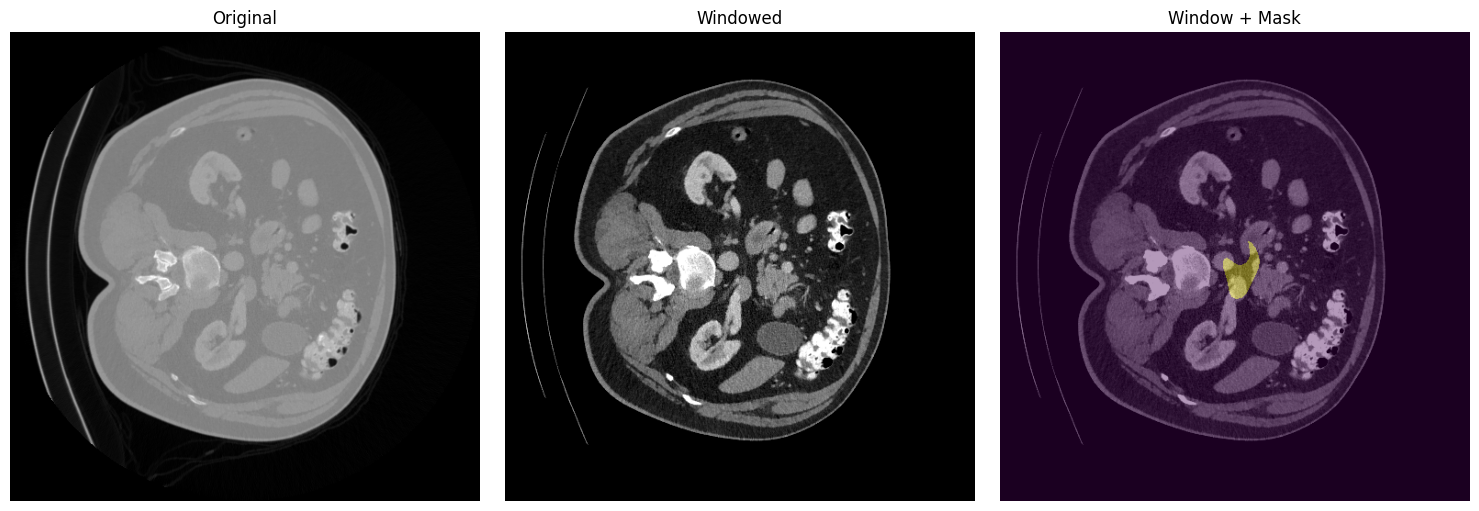

In [28]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.4 : WINDOWING VISUALIZATION
################################################################################

windowed = apply_window(volume)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(volume[:,:,mid], cmap='gray')
plt.title("Original")

plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(windowed[:,:,mid], cmap='gray')
plt.title("Windowed")

plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(windowed[:,:,mid], cmap='gray')
plt.imshow(mask[:,:,mid], alpha=0.4)

plt.title("Window + Mask")

plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_ROOT,
        "Figures",
        "Figure_11_Windowing.png"),
    dpi=600)

plt.show()

In [29]:
################################################################################
# PANTHER-Net
# UTILITY SECTION
# ZIP ALL GENERATED OUTPUTS
################################################################################

import os
import zipfile

# ==============================================================================
# OUTPUT DIRECTORY
# ==============================================================================

OUTPUT_DIR = "/kaggle/working"

ZIP_NAME = "PANTHER_Phase1_Outputs.zip"

ZIP_PATH = os.path.join(OUTPUT_DIR, ZIP_NAME)

# ==============================================================================
# FILE EXTENSIONS TO INCLUDE
# ==============================================================================

VALID_EXTENSIONS = (
    ".png",
    ".jpg",
    ".jpeg",
    ".csv",
    ".xlsx",
    ".txt",
    ".json",
    ".pdf",
    ".log"
)

# ==============================================================================
# CREATE ZIP
# ==============================================================================

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk(OUTPUT_DIR):

        for file in files:

            if file == ZIP_NAME:
                continue

            if file.lower().endswith(VALID_EXTENSIONS):

                filepath = os.path.join(root, file)

                arcname = os.path.relpath(filepath, OUTPUT_DIR)

                zipf.write(filepath, arcname)

print("="*80)
print("ZIP FILE CREATED SUCCESSFULLY")
print("="*80)
print(ZIP_PATH)
print("="*80)

ZIP FILE CREATED SUCCESSFULLY
/kaggle/working/PANTHER_Phase1_Outputs.zip


In [30]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.23 : PANCREAS BOUNDING BOX ANALYSIS
################################################################################

import numpy as np
import pandas as pd
import nibabel as nib
from tqdm import tqdm
import os

bounding_boxes = []

for case in tqdm(label_files):

    mask = nib.load(os.path.join(LABEL_PATH, case)).get_fdata()

    # Pancreas + Tumor
    organ = (mask > 0)

    coords = np.argwhere(organ)

    xmin, ymin, zmin = coords.min(axis=0)
    xmax, ymax, zmax = coords.max(axis=0)

    bounding_boxes.append({

        "Case":case,

        "Xmin":xmin,
        "Xmax":xmax,

        "Ymin":ymin,
        "Ymax":ymax,

        "Zmin":zmin,
        "Zmax":zmax,

        "Width":xmax-xmin+1,
        "Height":ymax-ymin+1,
        "Depth":zmax-zmin+1

    })

bbox_df = pd.DataFrame(bounding_boxes)

bbox_df.head()

100%|██████████| 281/281 [01:16<00:00,  3.69it/s]


,Case,Xmin,Xmax,Ymin,Ymax,Zmin,Zmax,Width,Height,Depth
0,pancreas_001.nii,144,298,261,344,33,61,155,84,29
1,pancreas_004.nii,121,331,183,306,37,71,211,124,35
2,pancreas_005.nii,182,312,206,302,26,65,131,97,40
3,pancreas_006.nii,145,315,232,321,34,58,171,90,25
4,pancreas_010.nii,134,294,201,296,35,107,161,96,73


In [31]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.24 : SAVE BOUNDING BOX STATISTICS
################################################################################

bbox_df.to_csv(
    "BoundingBox_Statistics.csv",
    index=False
)

print("Bounding box statistics saved successfully.")

Bounding box statistics saved successfully.


In [32]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.25 : BOUNDING BOX SUMMARY
################################################################################

print("="*90)

print(bbox_df.describe())

print("="*90)

             Xmin        Xmax        Ymin        Ymax        Zmin        Zmax  \
count  281.000000  281.000000  281.000000  281.000000  281.000000  281.000000   
mean   145.263345  303.697509  231.498221  321.647687   30.199288   60.487544   
std     24.149128   18.050454   23.505034   17.825956   32.996690   40.205997   
min     77.000000  257.000000  163.000000  264.000000    0.000000   19.000000   
25%    129.000000  291.000000  216.000000  310.000000   18.000000   49.000000   
50%    145.000000  305.000000  233.000000  323.000000   25.000000   57.000000   
75%    161.000000  316.000000  248.000000  332.000000   34.000000   66.000000   
max    210.000000  361.000000  298.000000  372.000000  461.000000  608.000000   

            Width      Height       Depth  
count  281.000000  281.000000  281.000000  
mean   159.434164   91.149466   31.288256  
std     30.968477   21.429763   11.662769  
min     74.000000   44.000000   12.000000  
25%    138.000000   77.000000   26.000000  
50%   

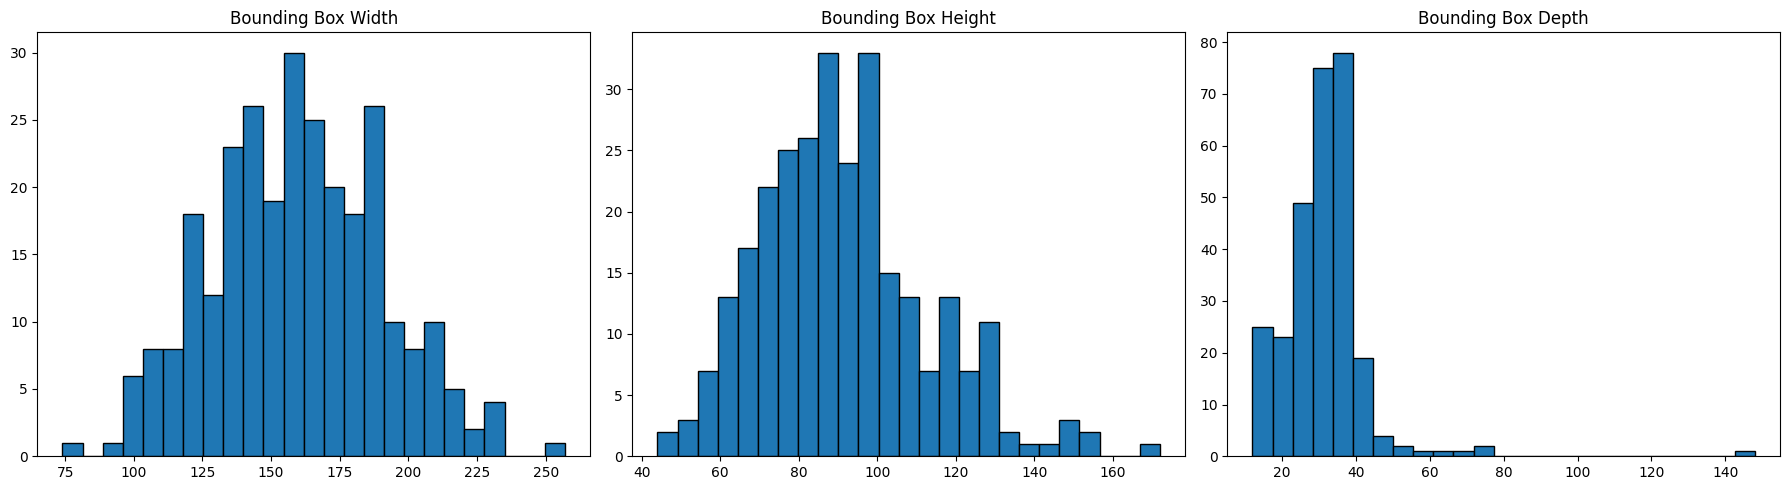

In [33]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.26 : BOUNDING BOX SIZE DISTRIBUTION
################################################################################

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,3, figsize=(18,5))

ax[0].hist(bbox_df["Width"],
           bins=25,
           edgecolor='black')

ax[0].set_title("Bounding Box Width")

ax[1].hist(bbox_df["Height"],
           bins=25,
           edgecolor='black')

ax[1].set_title("Bounding Box Height")

ax[2].hist(bbox_df["Depth"],
           bins=25,
           edgecolor='black')

ax[2].set_title("Bounding Box Depth")

plt.tight_layout()

plt.savefig(
    "Figure_12_BoundingBox_Distribution.png",
    dpi=600)

plt.show()

In [34]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.27 : LARGEST PANCREAS ROI
################################################################################

largest_width = bbox_df["Width"].max()
largest_height = bbox_df["Height"].max()
largest_depth = bbox_df["Depth"].max()

print("="*80)

print("Largest Bounding Box")

print("="*80)

print("Width :", largest_width)

print("Height:", largest_height)

print("Depth :", largest_depth)

Largest Bounding Box
Width : 257
Height: 172
Depth : 148


In [35]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.28 : RECOMMENDED INPUT SIZE
################################################################################

recommended_x = int(np.ceil(largest_width/16)*16)
recommended_y = int(np.ceil(largest_height/16)*16)
recommended_z = int(np.ceil(largest_depth/16)*16)

print("="*80)

print("RECOMMENDED INPUT SIZE")

print("="*80)

print(f"{recommended_x} x {recommended_y} x {recommended_z}")

print("="*80)

RECOMMENDED INPUT SIZE
272 x 176 x 160


In [36]:
################################################################################
# PANTHER-Net
# PHASE 1 : DATASET ANALYSIS
# SECTION 1.29 : VISUALIZE LARGEST ROI
################################################################################

largest_case = bbox_df.sort_values(
    by=["Width","Height","Depth"],
    ascending=False
).iloc[0]["Case"]

print("Largest ROI Case :", largest_case)

Largest ROI Case : pancreas_052.nii


In [37]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.1 : DEFINE PREPROCESSING PARAMETERS
################################################################################

# CT Window
WINDOW_MIN = -150
WINDOW_MAX = 250

# ROI Margin (obtained from dataset analysis)
MARGIN_X = 20
MARGIN_Y = 20
MARGIN_Z = 10

# Target Volume Size (Frozen)
TARGET_SIZE = (192, 192, 64)

print("="*80)
print("PREPROCESSING PARAMETERS")
print("="*80)

print("Window           :", WINDOW_MIN, "to", WINDOW_MAX)
print("ROI Margin       :", (MARGIN_X, MARGIN_Y, MARGIN_Z))
print("Target Size      :", TARGET_SIZE)

print("="*80)

PREPROCESSING PARAMETERS
Window           : -150 to 250
ROI Margin       : (20, 20, 10)
Target Size      : (192, 192, 64)


In [38]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.2 : CT WINDOWING
################################################################################

def ct_window(volume,
              lower=WINDOW_MIN,
              upper=WINDOW_MAX):

    volume = np.clip(volume,
                     lower,
                     upper)

    return volume

In [39]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.3 : AIEM (VERSION-1)
################################################################################

def AIEM(volume):

    # Step 1 : Windowing
    volume = ct_window(volume)

    # Step 2 : Normalize to [0,1]
    volume = (volume - volume.min()) / (volume.max() - volume.min() + 1e-8)

    # Step 3 : Gamma Correction
    gamma = 0.9

    volume = np.power(volume, gamma)

    return volume

In [40]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.4 : ROI EXTRACTION
################################################################################

def extract_roi(image,
                mask,
                margin=(20,20,10)):

    coords = np.argwhere(mask > 0)

    xmin, ymin, zmin = coords.min(axis=0)
    xmax, ymax, zmax = coords.max(axis=0)

    xmin = max(0, xmin-margin[0])
    ymin = max(0, ymin-margin[1])
    zmin = max(0, zmin-margin[2])

    xmax = min(image.shape[0], xmax+margin[0])
    ymax = min(image.shape[1], ymax+margin[1])
    zmax = min(image.shape[2], zmax+margin[2])

    image = image[
        xmin:xmax,
        ymin:ymax,
        zmin:zmax
    ]

    mask = mask[
        xmin:xmax,
        ymin:ymax,
        zmin:zmax
    ]

    return image, mask

In [41]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.5 : RESIZE TO TARGET SIZE
################################################################################

from scipy.ndimage import zoom

def resize_volume(image,
                  mask,
                  target_size=TARGET_SIZE):

    scale = (

        target_size[0]/image.shape[0],

        target_size[1]/image.shape[1],

        target_size[2]/image.shape[2]

    )

    image = zoom(
        image,
        scale,
        order=3
    )

    mask = zoom(
        mask,
        scale,
        order=0
    )

    return image, mask

In [42]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.6 : COMPLETE PIPELINE
################################################################################

sample_case = image_files[0]

image = nib.load(
    os.path.join(
        IMAGE_PATH,
        sample_case)
).get_fdata()

mask = nib.load(
    os.path.join(
        LABEL_PATH,
        sample_case)
).get_fdata()

print("Original Shape :", image.shape)

image = AIEM(image)

image, mask = extract_roi(
    image,
    mask,
    margin=(20,20,10)
)

print("ROI Shape :", image.shape)

# ----------------------------------------------------------
# Verify pancreas and tumor after cropping
# ----------------------------------------------------------

pancreas_voxels = np.sum(mask == 1)
tumor_voxels    = np.sum(mask == 2)

print(f"Pancreas Voxels : {pancreas_voxels:,}")
print(f"Tumor Voxels    : {tumor_voxels:,}")

if tumor_voxels == 0:
    print("WARNING : Tumor removed during ROI extraction!")

if pancreas_voxels == 0:
    print("WARNING : Pancreas removed during ROI extraction!")

################################################################################
# RESIZE ROI
################################################################################

image, mask = resize_volume(
    image,
    mask
)

print("Final Shape :", image.shape)

Original Shape : (512, 512, 110)
ROI Shape : (194, 123, 48)
Pancreas Voxels : 39,557
Tumor Voxels    : 26,153
Final Shape : (192, 192, 64)


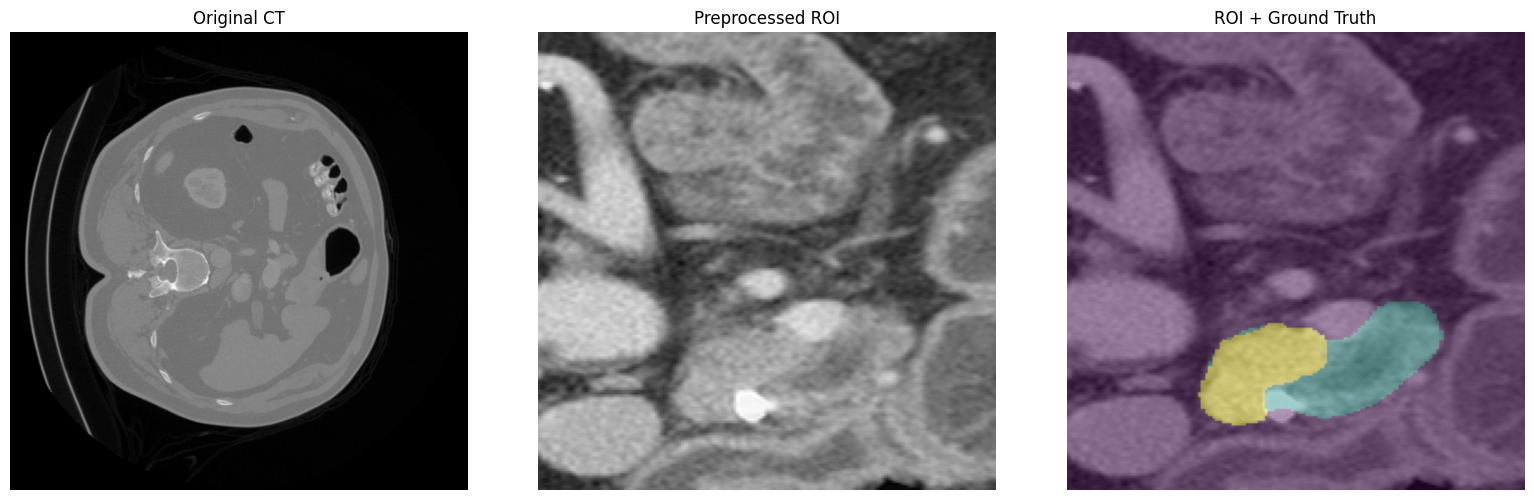

In [43]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.7 : PREPROCESSING VISUALIZATION
################################################################################

mid = image.shape[2]//2

plt.figure(figsize=(16,5))

plt.subplot(1,3,1)
plt.imshow(volume[:,:,volume.shape[2]//2], cmap='gray')
plt.title("Original CT")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(image[:,:,mid], cmap='gray')
plt.title("Preprocessed ROI")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(image[:,:,mid], cmap='gray')
plt.imshow(mask[:,:,mid], alpha=0.4)
plt.title("ROI + Ground Truth")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_ROOT,
        "Figures",
        "Figure_13_Preprocessing.png"),
    dpi=600
)

plt.show()

In [44]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.8 : CREATE PREPROCESSED DATASET DIRECTORIES
################################################################################

import os

PREPROCESS_ROOT = "/kaggle/working/PANTHER_Preprocessed"

IMAGE_SAVE_PATH = os.path.join(PREPROCESS_ROOT, "images")
LABEL_SAVE_PATH = os.path.join(PREPROCESS_ROOT, "labels")

os.makedirs(IMAGE_SAVE_PATH, exist_ok=True)
os.makedirs(LABEL_SAVE_PATH, exist_ok=True)

print("="*80)
print("Preprocessed dataset folders created successfully.")
print("="*80)

Preprocessed dataset folders created successfully.


In [45]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.9 : PREPROCESS ENTIRE TRAINING DATASET
################################################################################

import numpy as np
import pandas as pd
import nibabel as nib

from tqdm import tqdm

preprocessing_log = []

for case in tqdm(image_files):

    # ----------------------------------------------------
    # Load Image
    # ----------------------------------------------------

    image = nib.load(
        os.path.join(IMAGE_PATH, case)
    ).get_fdata()

    # ----------------------------------------------------
    # Load Mask
    # ----------------------------------------------------

    mask = nib.load(
        os.path.join(LABEL_PATH, case)
    ).get_fdata()

    original_shape = image.shape

    # ----------------------------------------------------
    # AIEM
    # ----------------------------------------------------

    image = AIEM(image)

    # ----------------------------------------------------
    # ROI Extraction
    # ----------------------------------------------------

    image, mask = extract_roi(
        image,
        mask,
        margin=(20,20,10)
    )

    roi_shape = image.shape

    pancreas_voxels = int(np.sum(mask == 1))
    tumor_voxels = int(np.sum(mask == 2))

    status = "OK"

    if pancreas_voxels == 0:
        status = "ERROR_NO_PANCREAS"

    if tumor_voxels == 0:
        status = "WARNING_NO_TUMOR"

    # ----------------------------------------------------
    # Resize
    # ----------------------------------------------------

    image, mask = resize_volume(
        image,
        mask,
        target_size=TARGET_SIZE
    )

    final_shape = image.shape

    # ----------------------------------------------------
    # Save Image
    # ----------------------------------------------------

    filename = case.replace(".nii","")

    np.save(
        os.path.join(
            IMAGE_SAVE_PATH,
            filename
        ),
        image.astype(np.float32)
    )

    np.save(
        os.path.join(
            LABEL_SAVE_PATH,
            filename
        ),
        mask.astype(np.uint8)
    )

    preprocessing_log.append({

        "Case":case,

        "OriginalShape":str(original_shape),

        "ROIShape":str(roi_shape),

        "FinalShape":str(final_shape),

        "PancreasVoxels":pancreas_voxels,

        "TumorVoxels":tumor_voxels,

        "Status":status

    })

100%|██████████| 281/281 [14:52<00:00,  3.18s/it]


In [46]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.10 : SAVE PREPROCESSING LOG
################################################################################

preprocessing_log = pd.DataFrame(preprocessing_log)

preprocessing_log.to_csv(

    os.path.join(
        PREPROCESS_ROOT,
        "preprocessing_log.csv"
    ),

    index=False

)

print("="*80)
print("Preprocessing completed successfully.")
print("="*80)

print(preprocessing_log.head())

Preprocessing completed successfully.
               Case    OriginalShape        ROIShape      FinalShape  \
0  pancreas_001.nii  (512, 512, 110)  (194, 123, 48)  (192, 192, 64)   
1  pancreas_004.nii  (512, 512, 107)  (250, 163, 54)  (192, 192, 64)   
2  pancreas_005.nii  (512, 512, 104)  (170, 136, 59)  (192, 192, 64)   
3  pancreas_006.nii  (512, 512, 101)  (210, 129, 44)  (192, 192, 64)   
4  pancreas_010.nii  (512, 512, 174)  (200, 135, 92)  (192, 192, 64)   

   PancreasVoxels  TumorVoxels Status  
0           39557        26153     OK  
1           71622        28448     OK  
2           71062         3609     OK  
3           70046         9244     OK  
4          116491        53193     OK  


In [47]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.11 : VERIFY PREPROCESSED DATASET
################################################################################

print("="*80)

print("Processed Images :", len(os.listdir(IMAGE_SAVE_PATH)))

print("Processed Labels :", len(os.listdir(LABEL_SAVE_PATH)))

print("="*80)

sample = np.load(
    os.path.join(
        IMAGE_SAVE_PATH,
        os.listdir(IMAGE_SAVE_PATH)[0]
    )
)

sample_mask = np.load(
    os.path.join(
        LABEL_SAVE_PATH,
        os.listdir(LABEL_SAVE_PATH)[0]
    )
)

print("Sample Image Shape :", sample.shape)

print("Sample Mask Shape :", sample_mask.shape)

print("Unique Labels :", np.unique(sample_mask))

Processed Images : 281
Processed Labels : 281
Sample Image Shape : (192, 192, 64)
Sample Mask Shape : (192, 192, 64)
Unique Labels : [0 1 2]


In [48]:
################################################################################
# PANTHER-Net
# PHASE 2 : ADAPTIVE CT PREPROCESSING FRAMEWORK
# SECTION 2.12 : ZIP PREPROCESSED DATASET
################################################################################

import zipfile

zip_path = "/kaggle/working/PANTHER_Preprocessed.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk(PREPROCESS_ROOT):

        for file in files:

            filepath = os.path.join(root, file)

            arcname = os.path.relpath(filepath, PREPROCESS_ROOT)

            zipf.write(filepath, arcname)

print("="*80)
print("ZIP CREATED")
print("="*80)
print(zip_path)

ZIP CREATED
/kaggle/working/PANTHER_Preprocessed.zip


In [49]:
################################################################################
# PANTHER-Net
# PHASE 3 : MODEL DEVELOPMENT
# SECTION 3.1 : IMPORT LIBRARIES
################################################################################

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from sklearn.model_selection import train_test_split

print("="*80)
print("PyTorch Version :", torch.__version__)
print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

print("="*80)

PyTorch Version : 2.10.0+cu128
CUDA Available  : True
GPU : Tesla T4
